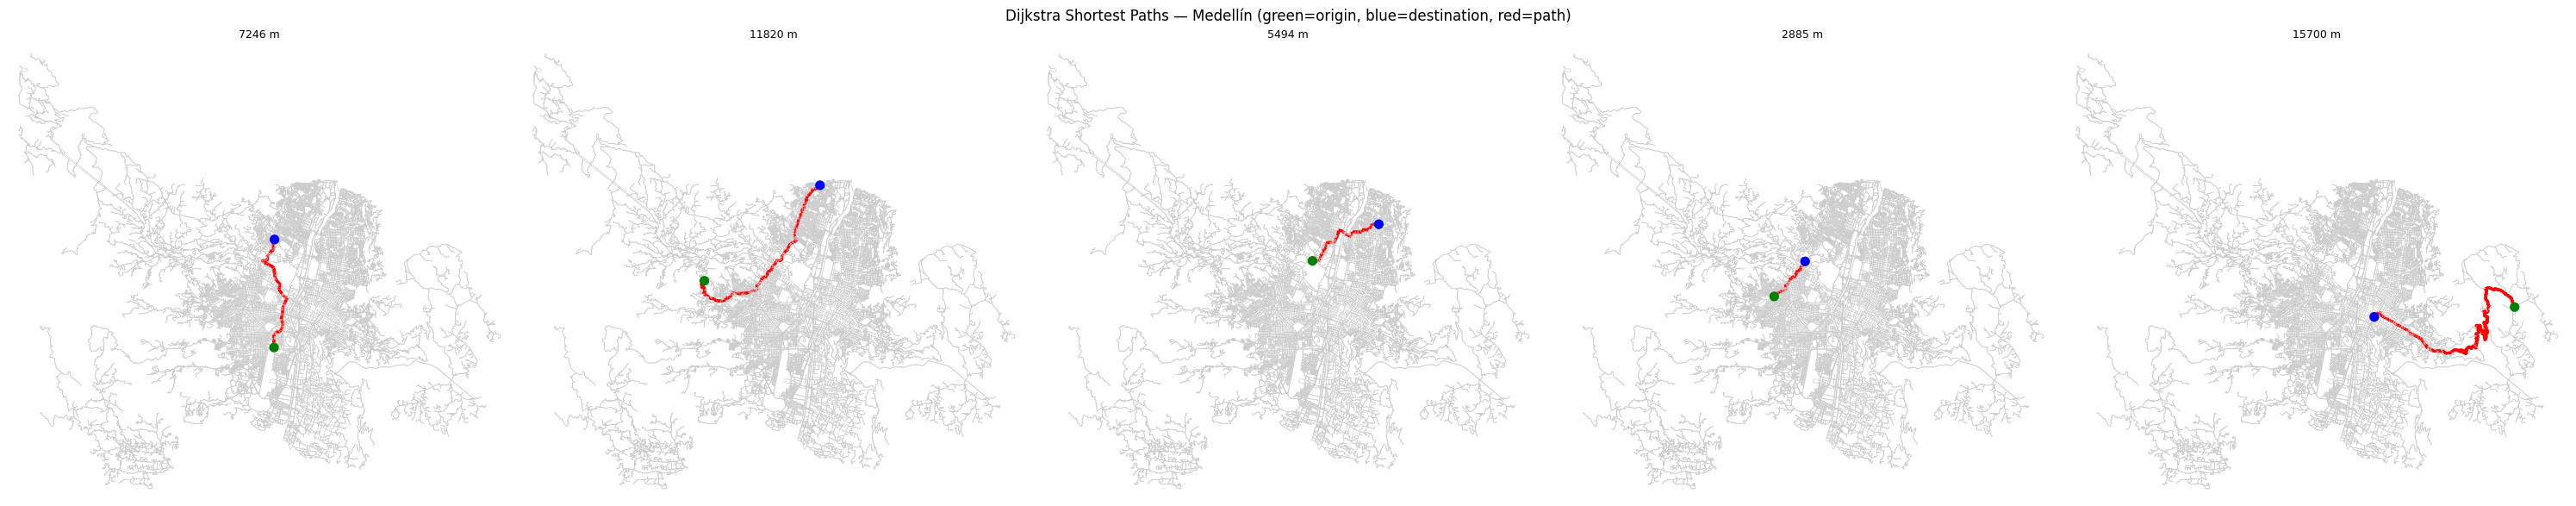

In [3]:
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import random

G = ox.load_graphml('/Users/gregorioperez/Documents/Maestria/Investigacion/mde_dijsktra/medellin_drive_with_elevation.graphml')

# Use geometric length as edge weight
for u, v, data in G.edges(data=True):
    data['weight'] = float(data.get('length', 1))

nodes = list(G.nodes())

fig, axes = plt.subplots(1, 5, figsize=(30, 6))

for ax in axes:
    source, target = random.sample(nodes, 2)
    try:
        path = nx.dijkstra_path(G, source, target, weight='weight')
        path_edges = list(zip(path[:-1], path[1:]))
        
        ec = ['red' if (u, v) in path_edges or (v, u) in path_edges else '#cccccc' for u, v, k in G.edges(keys=True)]
        ew = [2.5 if (u, v) in path_edges or (v, u) in path_edges else 0.5 for u, v, k in G.edges(keys=True)]
        
        ox.plot_graph(G, ax=ax, edge_color=ec, edge_linewidth=ew, node_size=0, show=False, close=False)
        
        src_x, src_y = G.nodes[source]['x'], G.nodes[source]['y']
        tgt_x, tgt_y = G.nodes[target]['x'], G.nodes[target]['y']
        ax.scatter([src_x, tgt_x], [src_y, tgt_y], c=['green', 'blue'], s=50, zorder=5)
        
        dist = nx.dijkstra_path_length(G, source, target, weight='weight')
        ax.set_title(f'{dist:.0f} m', fontsize=9)
    except nx.NetworkXNoPath:
        ox.plot_graph(G, ax=ax, node_size=0, show=False, close=False)
        ax.set_title('No path', fontsize=9)

plt.suptitle('Dijkstra Shortest Paths — Medellín (green=origin, blue=destination, red=path)', fontsize=12)
plt.tight_layout()
plt.show()

In [6]:
print("Vertices:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Vertices: 15207
Edges: 36725


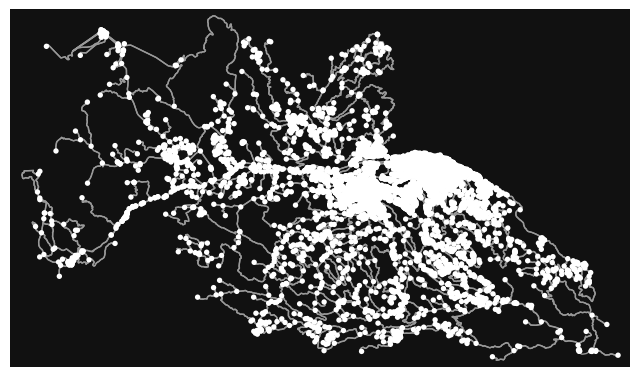

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [ ]:
ox.plot_graph(G)


In [6]:
# Map NetworkX scores back onto directed edges for ox.plot_graph
G = ox.load_graphml('/Users/gregorioperez/Documents/Maestria/Investigacion/mde_dijsktra/pereira_osmnx.graphml')

nx_directed_scores = []
for u, v, k in G.edges(keys=True):
    key = (u, v) if (u, v) in nx_edge_bc else (v, u)
    nx_directed_scores.append(nx_edge_bc.get(key, 0))

nx_scores = np.array(nx_directed_scores, dtype=float)
nx_scores_norm = (nx_scores - nx_scores.min()) / (nx_scores.max() - nx_scores.min() + 1e-9)

cmap = plt.cm.plasma
edge_colors = [cmap(s) for s in nx_scores_norm]
edge_widths = [0.3 + 2.5 * s for s in nx_scores_norm]

fig, ax = ox.plot_graph(
    G,
    edge_color=edge_colors,
    edge_linewidth=edge_widths,
    node_size=0,
    bgcolor='black',
    show=False,
    close=False,
    figsize=(14, 14)
)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=nx_scores.min(), vmax=nx_scores.max()))
sm.set_array([])
plt.colorbar(sm, ax=ax, fraction=0.02, pad=0.02, label='Betweenness count (NetworkX)')
ax.set_title('Edge Betweenness Centrality (NetworkX) — Medellin Urbano', color='white', fontsize=14)
plt.tight_layout()
#plt.savefig('/Users/gregorioperez/Documents/Maestria/Investigacion/mde_dijsktra/mde_urban_bet.pdf', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'nx_edge_bc' is not defined